# Demo fo synthesizing mental Maps

last update: 04/02/2025

This code is a quick demo how we aggregate/synthesize mental maps

*Note:* 

1. Calculate the number of times a node exists across all the Graphs 

$$
\vec{V}_{G_{i,\cdot}} = \sum_{j=0}^{{CLD_{N}}} {V}_{G_{ij}} > NodeThreshold
$$

where $i \in \mathcal{M}$ (number of variables) and $j \in \mathcal{N}$ (number of graphs).

2. Calculate the number of times a edge exists between two ndoes in all the graphs 

$$
(VarSource, VarTarget) = (V'_{G_{i,\cdot}}, V'_{G_{i,\cdot}}) = \sum_{j=0}^{{CLD_{N}}} (\vec{V}_{G_{i,\cdot}}, \vec{V}_{G_{i,\cdot}}) > EdgeThreshold
$$

where $i \in \mathcal{M}$ (number of variables) and $j \in \mathcal{N}$ (number of graphs).





# Import


In [4]:
#auto reload
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [74]:

import networkx as nx
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
import pandas as pd
import gravis as gv
import seaborn as sns

In [6]:
import os
import sys
from pathlib import Path

cwd = os.getcwd()
parent_dir = Path(cwd).parent
# Add the parent directory to the Python path
sys.path.append(str(parent_dir))
print(sys.path)

['/Users/gl665/.pyenv/versions/3.11.8/lib/python311.zip', '/Users/gl665/.pyenv/versions/3.11.8/lib/python3.11', '/Users/gl665/.pyenv/versions/3.11.8/lib/python3.11/lib-dynload', '', '/Users/gl665/Documents/Phrame-MentalMaps-1/.venv/lib/python3.11/site-packages', '/Users/gl665/Documents/Phrame-MentalMaps-1']


In [7]:
from old_code.cld_nx import cld_nx_properties, combine_graphs_with_node_attributes
from old_code import cld_nx

from src.graph_processing.graph_properties import CLDGraph
from src.graph_processing.link_trimmer import LinkTrimmer
from src.data_management.data_loader import DataLoader
from src.graph_processing.graph_visual import GraphVisualizer

# Canonical Example

In [8]:
# create test cases for the link trimming.

G1 = nx.DiGraph()
G1.add_nodes_from(["A", "B", "C", "D"])
G1.add_edge("A", "B", weight=1)
G1.add_edge("B", "C", weight=1)
G1.add_edge("C", "D", weight=1)

G2 = nx.DiGraph()
G2.add_nodes_from(["A", "D"])
G2.add_edge("A", "D", weight=1)

G3 = nx.DiGraph()
G3.add_nodes_from(["A", "C", "D", "E"])
G3.add_edge("A", "C", weight=1)
G3.add_edge("C", "D", weight=1)
G3.add_edge("E", "A", weight=1)

G4 = nx.DiGraph()
G4.add_nodes_from(["A", "E"])
G4.add_edge("A", "E", weight=1)

G_Raw = nx.DiGraph()
G_Raw.add_nodes_from(["A", "B", "C", "D", "E"])
G_Raw.add_edge("A", "B", weight=1)
G_Raw.add_edge("B", "C", weight=1)
G_Raw.add_edge("C", "D", weight=1)
G_Raw.add_edge("A", "D", weight=1)
G_Raw.add_edge("A", "E", weight=1)
G_Raw.add_edge("E", "A", weight=1)

G_Trimmed = nx.DiGraph()
G_Trimmed.add_nodes_from(["A", "C", "D", "E"])
G_Trimmed.add_edge("A", "C", weight=1)
G_Trimmed.add_edge("C", "D", weight=1)
G_Trimmed.add_edge("A", "E", weight=1)
G_Trimmed.add_edge("E", "A", weight=1)


G_test = nx.DiGraph()
G_test.add_nodes_from(["A", "B", "C", "D", "E"])
G_test.add_edge("A", "B", weight=10)
G_test.add_edge("B", "C", weight=1)
G_test.add_edge("C", "D", weight=1)
G_test.add_edge("A", "E", weight=1)
G_test.add_edge("E", "D", weight=1)

In [9]:

G5 = nx.DiGraph()
G5.add_nodes_from(["A", "B", "C", "D"])
G5.add_edge("A", "B", weight=1)
G5.add_edge("B", "C", weight=1)
G5.add_edge("C", "D", weight=1)
G5.add_edge("D", "A", weight=1)

G6 = nx.DiGraph()
G6.add_nodes_from(["A", "B"])
G6.add_edge("A", "B", weight=1)

G7 = nx.DiGraph()
G7.add_nodes_from(["A", "C", "E"])
G7.add_edge("A", "C", weight=1)
G7.add_edge("E", "A", weight=1)

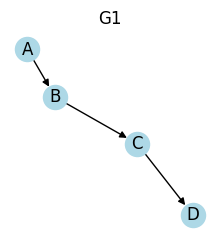

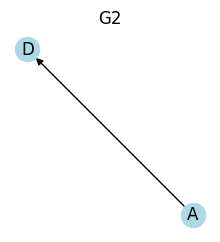

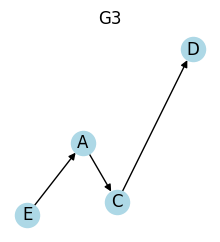

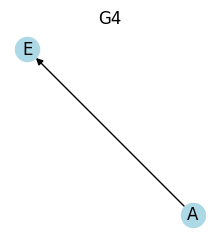

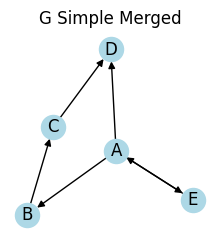

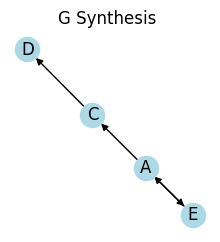

In [59]:
# print nx graph
# change the size of the graph

plt.figure(figsize=(2, 2))
nx.draw(G1, with_labels=True, node_color="lightblue")
plt.title("G1")
plt.show()

plt.figure(figsize=(2, 2))
nx.draw(G2, with_labels=True, node_color="lightblue")
plt.title("G2")
plt.show()

plt.figure(figsize=(2, 2))
nx.draw(G3, with_labels=True, node_color="lightblue")
plt.title("G3")
plt.show()

plt.figure(figsize=(2, 2))
nx.draw(G4, with_labels=True, node_color="lightblue")
plt.title("G4")
plt.show()

plt.figure(figsize=(2, 2))
nx.draw(G_Raw, with_labels=True, node_color="lightblue")
plt.title("G Simple Merged")
plt.show()

plt.figure(figsize=(2, 2))
nx.draw(G_Trimmed, with_labels=True, node_color="lightblue")
plt.title("G Synthesis ")
plt.show()

In [56]:
list_of_graphs = [G1, G2, G3, G4]

link_trimmer = LinkTrimmer(list_of_graphs)

EDGE_THRESHOLD = 0
NODE_THRESHOLD = 0
print(
    f"When the node threshold is {NODE_THRESHOLD} and the edge threshold is {EDGE_THRESHOLD}")


nx_graph = link_trimmer.get_trimmed_graph(
    trimmed_edges_threshold=EDGE_THRESHOLD, trimmed_nodes_threshold=NODE_THRESHOLD)

trimmed_graph = CLDGraph(nx_graph)  # TODO: change back to nx_graph
trimmed_graph = trimmed_graph.build_CLD_graph()
print("Graph Properties: ")
print("Number of Nodes: ", trimmed_graph.graph_properties()['num_nodes'])
print("Number of Edges: ", trimmed_graph.graph_properties()['num_edges'])
print("--------------------------------")
print("Node Properties:     ")
print("Variable = number of times it appears in the all the graphs")
for node, attr in trimmed_graph.nodes(data=True):

    print(node, "=", attr['weight'])

print("--------------------------------")
print("Edge Properties:     ")
print("Causal Links = number of times it appears in the all the graphs")
for v, u, attr in trimmed_graph.edges(data=True):
    print((v, u), "=", attr['weight'])

gv_graph = trimmed_graph.gravis_settings()
gv.d3(gv_graph.to_gravis(),

      node_label_data_source='label',
      show_node_label_border=True,
      node_size_data_source='node_size',
      use_node_size_normalization=False,
      show_node_image=False,
      node_hover_neighborhood=True,

      node_size_normalization_min=1,
      node_size_normalization_max=4,
      node_label_rotation=15,
      node_label_size_factor=1,
      show_edge_label=True,
      node_hover_tooltip=True,

      edge_hover_tooltip=True,
      edge_label_data_source='edge_label',
      edge_size_data_source='edge_size',
      use_edge_size_normalization=True,
      edge_size_normalization_min=0.5,
      edge_size_normalization_max=5,
      edge_curvature=0.5,
      node_drag_fix=True,

      show_menu_toggle_button=True,
      links_force_distance=200,
      many_body_force_strength=-100,
      graph_height=200)

When the node threshold is 0 and the edge threshold is 0
Graph Properties: 
Number of Nodes:  5
Number of Edges:  7
--------------------------------
Node Properties:     
Variable = number of times it appears in the all the graphs
C = 2
D = 3
B = 1
A = 4
E = 2
--------------------------------
Edge Properties:     
Causal Links = number of times it appears in the all the graphs
('C', 'D') = 2
('B', 'C') = 1
('A', 'B') = 1
('A', 'D') = 1
('A', 'C') = 1
('A', 'E') = 1
('E', 'A') = 1


In [60]:

EDGE_THRESHOLD = 0
NODE_THRESHOLD = 1

list_of_graphs = [G1, G2, G3, G4]

link_trimmer = LinkTrimmer(list_of_graphs)

print(
    f"When the node threshold is {NODE_THRESHOLD} and the edge threshold is {EDGE_THRESHOLD}")


nx_graph = link_trimmer.get_trimmed_graph(
    trimmed_edges_threshold=EDGE_THRESHOLD, trimmed_nodes_threshold=NODE_THRESHOLD)

trimmed_graph = CLDGraph(nx_graph)  # TODO: change back to nx_graph
trimmed_graph = trimmed_graph.build_CLD_graph()
print("Graph Properties: ")
print("Number of Nodes: ", trimmed_graph.graph_properties()['num_nodes'])
print("Number of Edges: ", trimmed_graph.graph_properties()['num_edges'])
print("--------------------------------")
print("Node Properties:     ")
print("Variable = number of times it appears in the all the graphs")
for node, attr in trimmed_graph.nodes(data=True):

    print(node, "=", attr['weight'])

print("--------------------------------")
print("Edge Properties:     ")
print("Causal Links = number of times it appears in the all the graphs")
for v, u, attr in trimmed_graph.edges(data=True):
    print((v, u), "=", attr['weight'])

gv_graph = trimmed_graph.gravis_settings()
gv.d3(gv_graph.to_gravis(),

      node_label_data_source='label',
      show_node_label_border=True,
      node_size_data_source='node_size',
      use_node_size_normalization=False,
      show_node_image=False,
      node_hover_neighborhood=True,

      node_size_normalization_min=1,
      node_size_normalization_max=4,
      node_label_rotation=15,
      node_label_size_factor=1,
      show_edge_label=True,
      node_hover_tooltip=True,

      edge_hover_tooltip=True,
      edge_label_data_source='edge_label',
      edge_size_data_source='edge_size',
      use_edge_size_normalization=True,
      edge_size_normalization_min=0.5,
      edge_size_normalization_max=5,
      edge_curvature=0.5,
      node_drag_fix=True,

      show_menu_toggle_button=True,
      links_force_distance=200,
      many_body_force_strength=-100,
      graph_height=200)

When the node threshold is 1 and the edge threshold is 0
Graph Properties: 
Number of Nodes:  4
Number of Edges:  5
--------------------------------
Node Properties:     
Variable = number of times it appears in the all the graphs
C = 2
D = 3
E = 2
A = 4
--------------------------------
Edge Properties:     
Causal Links = number of times it appears in the all the graphs
('C', 'D') = 2
('E', 'A') = 1
('A', 'D') = 1
('A', 'C') = 1
('A', 'E') = 1


# Synthesizing on the SYNCH Dataset 



In [63]:
save_data = DataLoader()

data = save_data.load_file(
    file_path="/Users/gl665/Documents/Phrame-MentalMaps-1/notebook/data/processed/list_of_org_graphs.pkl")

print(data)

[<networkx.classes.digraph.DiGraph object at 0x12dfaf150>, <networkx.classes.digraph.DiGraph object at 0x12f80da50>, <networkx.classes.digraph.DiGraph object at 0x12de8eb90>, <networkx.classes.digraph.DiGraph object at 0x12e0ae050>, <networkx.classes.digraph.DiGraph object at 0x12e5ded10>, <networkx.classes.digraph.DiGraph object at 0x12e219010>, <networkx.classes.digraph.DiGraph object at 0x12e5d9250>, <networkx.classes.digraph.DiGraph object at 0x12e190310>, <networkx.classes.digraph.DiGraph object at 0x12dee8310>, <networkx.classes.digraph.DiGraph object at 0x12e147390>, <networkx.classes.digraph.DiGraph object at 0x12e12c390>, <networkx.classes.digraph.DiGraph object at 0x12e1c0890>, <networkx.classes.digraph.DiGraph object at 0x12dff2110>, <networkx.classes.digraph.DiGraph object at 0x12e0cb650>, <networkx.classes.digraph.DiGraph object at 0x12e1d98d0>, <networkx.classes.digraph.DiGraph object at 0x12f85e250>]


In [100]:
i = 1
node_counts = []
edge_counts = []
for cld in data:
    cld_graph = CLDGraph(cld)
    cld_graph = cld_graph.build_CLD_graph()

    # Get graph properties using the method (not property)
    properties = cld_graph.graph_properties()

    # Append counts
    node_counts.append(properties["num_nodes"])
    edge_counts.append(properties["num_edges"])

    print(
        f"CLD {i}: Nodes = {properties['num_nodes']}, Edges = {properties['num_edges']}")
    i += 1

print("-----------------------------------")
print("Summary statistics of the 16 mental maps in the SYNCH dataset")

# Create a DataFrame with the counts
df_stats = pd.DataFrame({
    'Nodes': node_counts,
    'Edges': edge_counts
})


print(df_stats.describe().round(3))

CLD 1: Nodes = 110, Edges = 174
CLD 2: Nodes = 78, Edges = 125
CLD 3: Nodes = 85, Edges = 181
CLD 4: Nodes = 102, Edges = 183
CLD 5: Nodes = 112, Edges = 221
CLD 6: Nodes = 18, Edges = 61
CLD 7: Nodes = 35, Edges = 78
CLD 8: Nodes = 104, Edges = 187
CLD 9: Nodes = 137, Edges = 233
CLD 10: Nodes = 122, Edges = 279
CLD 11: Nodes = 103, Edges = 145
CLD 12: Nodes = 99, Edges = 181
CLD 13: Nodes = 83, Edges = 174
CLD 14: Nodes = 123, Edges = 291
CLD 15: Nodes = 110, Edges = 236
CLD 16: Nodes = 77, Edges = 182
-----------------------------------
Summary statistics of the 16 mental maps in the SYNCH dataset
         Nodes    Edges
count   16.000   16.000
mean    93.625  183.188
std     31.179   62.469
min     18.000   61.000
25%     81.750  166.750
50%    102.500  181.500
75%    110.500  224.000
max    137.000  291.000


In [101]:
EDGE_THRESHOLD = 0
NODE_THRESHOLD = 0

list_of_graphs = data

link_trimmer = LinkTrimmer(list_of_graphs)

print(
    f"When the node threshold is {NODE_THRESHOLD} and the edge threshold is {EDGE_THRESHOLD}")


nx_graph = link_trimmer.get_trimmed_graph(
    trimmed_edges_threshold=EDGE_THRESHOLD, trimmed_nodes_threshold=NODE_THRESHOLD)

trimmed_graph = CLDGraph(nx_graph)  # TODO: change back to nx_graph
trimmed_graph = trimmed_graph.build_CLD_graph()
print("Graph Properties: ")
print("Number of Nodes: ", trimmed_graph.graph_properties()['num_nodes'])
print("Number of Edges: ", trimmed_graph.graph_properties()['num_edges'])
print("--------------------------------")
print("Node Properties:     ")
print("Variable = number of times it appears in the all the graphs")
# Sort nodes by weight in descending order
sorted_nodes = sorted(trimmed_graph.nodes(data=True),
                      key=lambda x: x[1]['weight'], reverse=True)
# for node, attr in sorted_nodes:
#     print(node, "=", attr['weight'])

# print("--------------------------------")
# print("Edge Properties:     ")
# print("Causal Links = number of times it appears in the all the graphs")
# Sort edges by weight in descending order
# sorted_edges = sorted(trimmed_graph.edges(data=True),
#                       key=lambda x: x[2]['weight'], reverse=True)
# for v, u, attr in sorted_edges:
#     print((v, u), "=", attr['weight'])

gv_graph = trimmed_graph.gravis_settings()
gv.d3(gv_graph.to_gravis(),

      node_label_data_source='label',
      show_node_label_border=True,
      node_size_data_source='node_size',
      use_node_size_normalization=True,
      show_node_image=False,
      node_hover_neighborhood=True,

      node_size_normalization_min=0.5,
      node_size_normalization_max=40,
      node_label_rotation=15,
      node_label_size_factor=0.5,
      show_edge_label=True,
      node_hover_tooltip=True,

      edge_hover_tooltip=True,
      edge_label_data_source='edge_label',
      edge_size_data_source='edge_size',
      use_edge_size_normalization=True,
      edge_size_normalization_min=0.5,
      edge_size_normalization_max=5,
      edge_curvature=0.5,
      node_drag_fix=True,

      show_menu_toggle_button=True,
      links_force_distance=200,
      many_body_force_strength=-100,
      graph_height=1000)

When the node threshold is 0 and the edge threshold is 0
Graph Properties: 
Number of Nodes:  1308
Number of Edges:  2772
--------------------------------
Node Properties:     
Variable = number of times it appears in the all the graphs


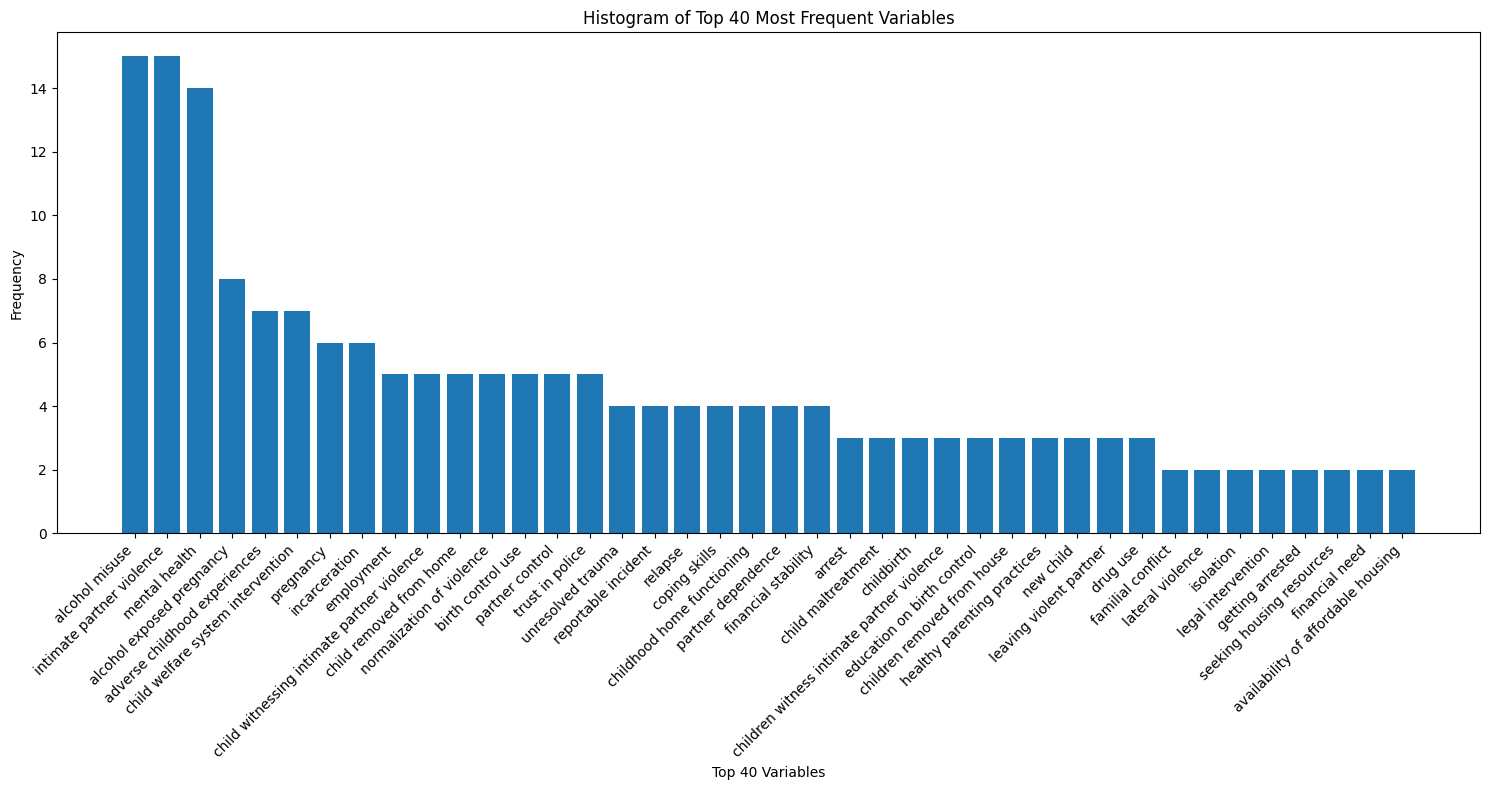

summary statistics on the number of counts of variable names
count    1308.000
mean        1.145
std         0.862
min         1.000
25%         1.000
50%         1.000
75%         1.000
max        15.000
Name: weight, dtype: float64


In [98]:
# pandas daaframe
# Convert list of tuples to dictionary first
node_dict = {node: attr['weight'] for node, attr in sorted_nodes}
node_counts = pd.DataFrame.from_dict(
    node_dict, orient='index', columns=['weight'])

# Sort values in descending order and get top 20
top_20_nodes = node_counts.sort_values('weight', ascending=False).head(40)

# Create histogram of node counts for top 20
plt.figure(figsize=(15, 8))
plt.bar(top_20_nodes.index, top_20_nodes['weight'])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Top 40 Variables')
plt.ylabel('Frequency')
plt.title('Histogram of Top 40 Most Frequent Variables')
plt.tight_layout()
plt.show()

print("summary statistics on the number of counts of variable names")
summary_stats = node_counts['weight'].describe().round(3)
print(summary_stats)

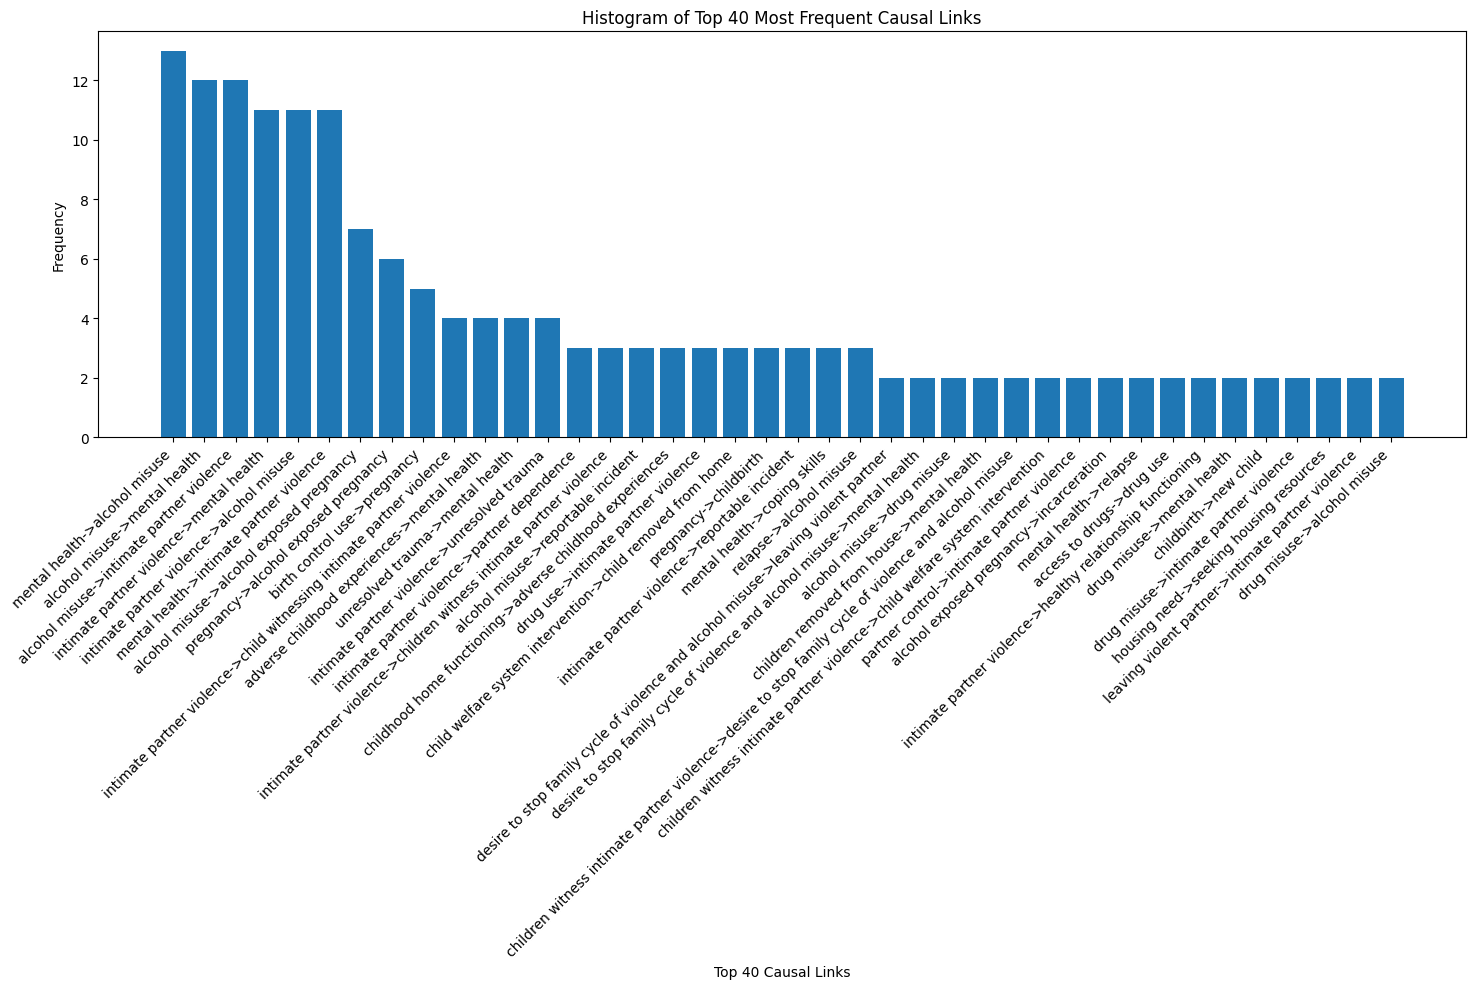

summary statistics on the number of counts of causal links
count    2772.000
mean        1.057
std         0.563
min         1.000
25%         1.000
50%         1.000
75%         1.000
max        13.000
Name: weight, dtype: float64


In [96]:
# Create dictionary of edge weights
edge_dict = {(u, v): attr['weight']
             for u, v, attr in trimmed_graph.edges(data=True)}
edge_counts = pd.DataFrame.from_dict(
    edge_dict, orient='index', columns=['weight'])

# Sort values in descending order and get top 40
top_40_edges = edge_counts.sort_values('weight', ascending=False).head(40)

# Create histogram of edge counts for top 40
plt.figure(figsize=(15, 10))
plt.bar([f"{u}->{v}" for u, v in top_40_edges.index], top_40_edges['weight'])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Top 40 Causal Links')
plt.ylabel('Frequency')
plt.title('Histogram of Top 40 Most Frequent Causal Links')
plt.tight_layout()
plt.show()

print("summary statistics on the number of counts of causal links")
summary_stats = edge_counts['weight'].describe().round(3)
print(summary_stats)

In [66]:
EDGE_THRESHOLD = 0
NODE_THRESHOLD = 1

list_of_graphs = data

link_trimmer = LinkTrimmer(list_of_graphs)

print(
    f"When the node threshold is {NODE_THRESHOLD} and the edge threshold is {EDGE_THRESHOLD}")


nx_graph = link_trimmer.get_trimmed_graph(
    trimmed_edges_threshold=EDGE_THRESHOLD, trimmed_nodes_threshold=NODE_THRESHOLD)

trimmed_graph = CLDGraph(nx_graph)  # TODO: change back to nx_graph
trimmed_graph = trimmed_graph.build_CLD_graph()
print("Graph Properties: ")
print("Number of Nodes: ", trimmed_graph.graph_properties()['num_nodes'])
print("Number of Edges: ", trimmed_graph.graph_properties()['num_edges'])
# print("--------------------------------")
# print("Node Properties:     ")
# print("Variable = number of times it appears in the all the graphs")
# for node, attr in trimmed_graph.nodes(data=True):

#     print(node, "=", attr['weight'])

# print("--------------------------------")
# print("Edge Properties:     ")
# print("Causal Links = number of times it appears in the all the graphs")
# for v, u, attr in trimmed_graph.edges(data=True):
#     print((v, u), "=", attr['weight'])

gv_graph = trimmed_graph.gravis_settings()
gv.d3(gv_graph.to_gravis(),

      node_label_data_source='label',
      show_node_label_border=True,
      node_size_data_source='node_size',
      use_node_size_normalization=True,
      show_node_image=False,
      node_hover_neighborhood=True,

      node_size_normalization_min=0.5,
      node_size_normalization_max=40,
      node_label_rotation=15,
      node_label_size_factor=0.5,
      show_edge_label=True,
      node_hover_tooltip=True,

      edge_hover_tooltip=True,
      edge_label_data_source='edge_label',
      edge_size_data_source='edge_size',
      use_edge_size_normalization=True,
      edge_size_normalization_min=0.5,
      edge_size_normalization_max=5,
      edge_curvature=0.5,
      node_drag_fix=True,

      show_menu_toggle_button=True,
      links_force_distance=200,
      many_body_force_strength=-100,
      graph_height=1000)

When the node threshold is 1 and the edge threshold is 0
Graph Properties: 
Number of Nodes:  76
Number of Edges:  208


In [99]:
EDGE_THRESHOLD = 1
NODE_THRESHOLD = 1

list_of_graphs = data

link_trimmer = LinkTrimmer(list_of_graphs)

print(
    f"When the node threshold is {NODE_THRESHOLD} and the edge threshold is {EDGE_THRESHOLD}")


nx_graph = link_trimmer.get_trimmed_graph(
    trimmed_edges_threshold=EDGE_THRESHOLD, trimmed_nodes_threshold=NODE_THRESHOLD)

trimmed_graph = CLDGraph(nx_graph)
trimmed_graph = trimmed_graph.build_CLD_graph()
print("Graph Properties: ")
print("Number of Nodes: ", trimmed_graph.graph_properties()['num_nodes'])
print("Number of Edges: ", trimmed_graph.graph_properties()['num_edges'])
# print("--------------------------------")
# print("Node Properties:     ")
# print("Variable = number of times it appears in the all the graphs")
# for node, attr in trimmed_graph.nodes(data=True):

#     print(node, "=", attr['weight'])

# print("--------------------------------")
# print("Edge Properties:     ")
# print("Causal Links = number of times it appears in the all the graphs")
# for v, u, attr in trimmed_graph.edges(data=True):
#     print((v, u), "=", attr['weight'])

gv_graph = trimmed_graph.gravis_settings()
gv.d3(gv_graph.to_gravis(),

      node_label_data_source='label',
      show_node_label_border=True,
      node_size_data_source='node_size',
      use_node_size_normalization=True,
      show_node_image=False,
      node_hover_neighborhood=True,

      node_size_normalization_min=0.5,
      node_size_normalization_max=40,
      node_label_rotation=15,
      node_label_size_factor=0.5,
      show_edge_label=True,
      node_hover_tooltip=True,

      edge_hover_tooltip=True,
      edge_label_data_source='edge_label',
      edge_size_data_source='edge_size',
      use_edge_size_normalization=True,
      edge_size_normalization_min=0.5,
      edge_size_normalization_max=5,
      edge_curvature=0.5,
      node_drag_fix=True,

      show_menu_toggle_button=True,
      links_force_distance=200,
      many_body_force_strength=-100,
      graph_height=1000)

When the node threshold is 1 and the edge threshold is 1
Graph Properties: 
Number of Nodes:  52
Number of Edges:  71


## Node/Edge numbers under thresholds

In [107]:
results = []

print("Synthesizing the SYNCH dataset with different edge and node thresholds")
list_of_graphs = data

link_trimmer = LinkTrimmer(list_of_graphs)

# Collect data
for EDGE_THRESHOLD in range(0, 5):
    for NODE_THRESHOLD in range(0, 5):
        nx_graph = link_trimmer.get_trimmed_graph(
            trimmed_edges_threshold=EDGE_THRESHOLD, trimmed_nodes_threshold=NODE_THRESHOLD)

        trimmed_graph = CLDGraph(nx_graph)
        trimmed_graph = trimmed_graph.build_CLD_graph()

        # Store results as a dictionary
        results.append({
            'Edge Threshold': EDGE_THRESHOLD,
            'Node Threshold': NODE_THRESHOLD,
            'Num Nodes': trimmed_graph.graph_properties()['num_nodes'],
            'Num Edges': trimmed_graph.graph_properties()['num_edges']
        })

# Create DataFrame
df_results = pd.DataFrame(results)

# Reshape the table to make it more readable
# Nodes table
nodes_table = df_results.pivot(
    index='Edge Threshold',
    columns='Node Threshold',
    values='Num Nodes'
)
print("Number of Nodes:")
print(nodes_table)

print("\nNumber of Edges:")
edges_table = df_results.pivot(
    index='Edge Threshold',
    columns='Node Threshold',
    values='Num Edges'
)
print(edges_table)

Synthesizing the SYNCH dataset with different edge and node thresholds
Number of Nodes:
Node Threshold     0   1   2   3   4
Edge Threshold                      
0               1308  76  30  21  13
1                 52  52  29  21  13
2                 19  19  19  16  10
3                  9   9   9   9   8
4                  6   6   6   6   6

Number of Edges:
Node Threshold     0    1   2   3   4
Edge Threshold                       
0               2772  208  74  46  27
1                 71   71  43  28  17
2                 23   23  23  20  12
3                 13   13  13  13  11
4                  9    9   9   9   9


In [106]:
print("\nEdge to Node Ratio:")
ratio_table = edges_table / nodes_table
print(ratio_table.round(2))


Edge to Node Ratio:
Node Threshold     0     1     2     3     4
Edge Threshold                              
0               2.12  2.74  2.47  2.19  2.08
1               1.37  1.37  1.48  1.33  1.31
2               1.21  1.21  1.21  1.25  1.20
3               1.44  1.44  1.44  1.44  1.38
4               1.50  1.50  1.50  1.50  1.50
